# Solving a system of nonlinear equations with SciPy

Multidimensional root finding means solving several equations for several unknowns simultaneously. This notebook uses `scipy.optimize.root` to find the intersections of two curves. The example is deliberately small enough to visualize, but it exhibits important features of larger nonlinear systems: multiple solutions, sensitivity to the initial guess, and possible failure even when solutions exist.

## Objectives

After working through this notebook, you should be able to:

- represent a system of nonlinear equations as a vector-valued residual function;
- use `scipy.optimize.root` with an initial guess;
- check both the solver status and the residual norm;
- explain why different initial guesses can lead to different solutions;
- recognize that solver failure does not by itself prove that no root exists.

## A circle and a parabola

Consider the system

$$
F_1(x, y) = x^2 + y^2 - 1 = 0,
$$

$$
F_2(x, y) = y - x^2 = 0.
$$

Here, $x$ and $y$ are the two unknown coordinates. The equation $F_1(x,y)=0$ describes the unit circle, and $F_2(x,y)=0$ describes the parabola $y=x^2$. A solution of the system is a point where both residuals, $F_1$ and $F_2$, are zero.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import root

## Visualizing the system

The zero contour of a function contains the points where that function equals zero. Plotting the zero contours of $F_1$ and $F_2$ makes the possible roots visible before we run a numerical solver.

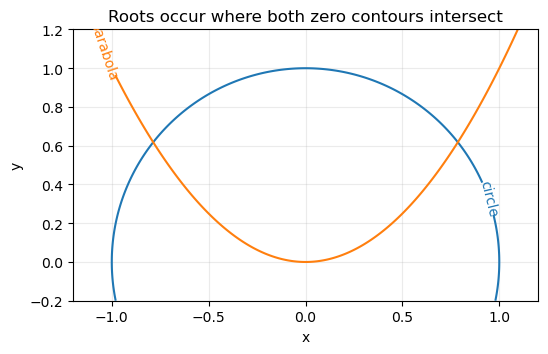

In [2]:
x_values = np.linspace(-1.2, 1.2, 301)
y_values = np.linspace(-0.2, 1.2, 301)
x_grid, y_grid = np.meshgrid(x_values, y_values)

circle_values = x_grid**2 + y_grid**2 - 1.0
parabola_values = y_grid - x_grid**2

fig, ax = plt.subplots(figsize=(6, 5))
circle_contour = ax.contour(
    x_grid, y_grid, circle_values, levels=[0.0], colors=["tab:blue"]
)
parabola_contour = ax.contour(
    x_grid, y_grid, parabola_values, levels=[0.0], colors=["tab:orange"]
)
ax.clabel(circle_contour, fmt={0.0: "circle"})
ax.clabel(parabola_contour, fmt={0.0: "parabola"})
ax.set(
    xlabel="x",
    ylabel="y",
    title="Roots occur where both zero contours intersect",
)
ax.set_aspect("equal")
ax.grid(alpha=0.25)

## Representing the residual function

Write the system as a vector-valued function $F:\mathbb{R}^2\rightarrow\mathbb{R}^2$,

$$
F(x,y) =
\begin{bmatrix}
F_1(x,y) \\
F_2(x,y)
\end{bmatrix}.
$$

`root` passes the unknown coordinates as one array and expects an array containing one residual for each equation.

In [3]:
def residual(coordinates: np.ndarray) -> np.ndarray:
    """Return the circle and parabola residuals at ``coordinates``."""
    x, y = coordinates
    return np.array([
        x**2 + y**2 - 1.0,
        y - x**2,
    ])

In [4]:
trial_point = np.array([1.0, 0.0])
print(f"F({trial_point}) = {residual(trial_point)}")

F([1. 0.]) = [ 0. -1.]


## Finding one root

A numerical root finder needs an initial guess. From the plot, $(0.8,0.6)$ appears to be close to the intersection with positive $x$. The solver returns an `OptimizeResult` containing the estimated root, convergence information, and the residual at the returned point.

In [5]:
initial_guess = np.array([0.8, 0.6])
result = root(residual, initial_guess)

print(f"solution:      {result.x}")
print(f"converged:     {result.success}")
print(f"residual:      {result.fun}")
print(f"residual norm: {np.linalg.norm(result.fun):.3e}")

solution:      [0.78615138 0.61803399]
converged:     True
residual:      [-2.22044605e-16 -1.11022302e-16]
residual norm: 2.483e-16


## Verifying the result

A plausible-looking coordinate pair is not sufficient evidence of convergence. Check `result.success` and the Euclidean residual norm $\lVert F(x,y)\rVert_2$, where $\lVert\cdot\rVert_2$ denotes the square root of the sum of the squared residuals.

This small problem also has an exact solution. Substituting $y=x^2$ into the circle equation gives $x^4+x^2-1=0$. If

$$
q = \frac{\sqrt{5}-1}{2},
$$

then the two roots are $(\sqrt{q},q)$ and $(-\sqrt{q},q)$. Here, $q$ is the positive solution for $x^2$.

In [6]:
q = (np.sqrt(5.0) - 1.0) / 2.0
positive_exact_root = np.array([np.sqrt(q), q])

assert result.success
assert np.linalg.norm(result.fun) < 1.0e-10
assert np.allclose(result.x, positive_exact_root)

print(f"exact root:     {positive_exact_root}")
print(f"absolute error: {np.abs(result.x - positive_exact_root)}")

exact root:     [0.78615138 0.61803399]
absolute error: [0.00000000e+00 2.22044605e-16]


## Initial guesses and multiple roots

`root` is a local solver: it searches from the supplied initial guess and does not automatically enumerate every solution. Starting on opposite sides of the $y$-axis leads to the two different intersections in this symmetric problem.

In [7]:
initial_guesses = np.array([
    [0.8, 0.6],
    [-0.8, 0.6],
])
results = [root(residual, guess) for guess in initial_guesses]

for guess, current_result in zip(initial_guesses, results, strict=True):
    residual_norm = np.linalg.norm(current_result.fun)
    print(
        f"initial guess {guess} -> root {current_result.x}, "
        f"success={current_result.success}, ||F||_2={residual_norm:.3e}"
    )

initial guess [0.8 0.6] -> root [0.78615138 0.61803399], success=True, ||F||_2=2.483e-16
initial guess [-0.8  0.6] -> root [-0.78615138  0.61803399], success=True, ||F||_2=2.483e-16


## A deliberately poor initial guess

The origin $(0,0)$ lies between the two roots, but geometric proximity alone does not make it a useful starting point. Run the next cell and compare the solver status and residual norm with the successful results.

In [8]:
poor_result = root(residual, np.array([0.0, 0.0]))

print(f"returned point: {poor_result.x}")
print(f"converged:      {poor_result.success}")
print(f"residual norm:  {np.linalg.norm(poor_result.fun):.3e}")
print(f"message:        {poor_result.message}")

returned point: [0. 0.]
converged:      False
residual norm:  1.000e+00
message:        The iteration is not making good progress, as measured by the 
 improvement from the last ten iterations.


The Jacobian matrix contains the first derivatives of all residuals with respect to all unknowns:

$$
J_F(x,y) =
\begin{bmatrix}
2x & 2y \\
-2x & 1
\end{bmatrix}.
$$

At $(0,0)$, the first row is zero and the matrix is singular, so the local derivative information does not provide a direction that improves both equations. The failed run therefore does **not** show that the system has no roots; the successful runs already demonstrate the opposite.

## Optional exploration: basins of attraction

We can repeat the solve over a grid of initial points to investigate two questions: which root does the solver reach, and how much work does convergence require? The first plot below classifies each initial point by outcome. The second reports `nfev`, the number of residual-function evaluations, for successful solves. `nfev` is a useful effort measure for the default `hybr` method, but it is not an iteration count.

A result is assigned to a root only when the solver reports success, the Euclidean residual norm is below `residual_tolerance`, and the returned point is within `root_tolerance` of a known root. All other results remain explicitly unclassified. The map therefore describes this solver method and these tolerances; it is not an intrinsic property of the equations alone.

The grid contains `grid_size**2` independent solves. Doubling `grid_size` approximately quadruples the computational work, so the chosen resolution is a compromise between detail and execution time.

In [9]:
coordinate_limit = 2.0
grid_size = 201
residual_tolerance = 1.0e-8
root_tolerance = 1.0e-6

initial_coordinates = np.linspace(
    -coordinate_limit, coordinate_limit, grid_size
)
known_roots = np.array([
    [-positive_exact_root[0], positive_exact_root[1]],
    positive_exact_root,
])

def scan_initial_points(method: str):
    """Run one root-finding method over the grid of initial points."""
    # -1 means unvalidated; 0 and 1 identify the known roots.
    basin = np.full((grid_size, grid_size), -1, dtype=np.int8)
    evaluations = np.empty((grid_size, grid_size), dtype=np.int16)
    reported_success = np.empty((grid_size, grid_size), dtype=bool)
    final_residual_norm = np.empty((grid_size, grid_size), dtype=float)

    for row_index, initial_y in enumerate(initial_coordinates):
        for column_index, initial_x in enumerate(initial_coordinates):
            initial_point = np.array([initial_x, initial_y])
            current_result = root(residual, initial_point, method=method)
            evaluations[row_index, column_index] = current_result.nfev
            reported_success[row_index, column_index] = current_result.success

            residual_norm = np.linalg.norm(current_result.fun)
            final_residual_norm[row_index, column_index] = residual_norm
            if current_result.success and residual_norm < residual_tolerance:
                distances = np.linalg.norm(known_roots - current_result.x, axis=1)
                closest_root = int(np.argmin(distances))
                if distances[closest_root] < root_tolerance:
                    basin[row_index, column_index] = closest_root

    return basin, evaluations, reported_success, final_residual_norm


(
    basin_id,
    function_evaluations,
    hybr_reported_success,
    hybr_residual_norm,
) = scan_initial_points("hybr")

In [10]:
outcome_labels = {
    -1: "failed or unclassified",
    0: "negative-x root",
    1: "positive-x root",
}

for outcome, label in outcome_labels.items():
    outcome_mask = basin_id == outcome
    evaluation_counts = function_evaluations[outcome_mask]
    percentage = 100.0 * evaluation_counts.size / basin_id.size
    print(
        f"{label:23s}: {percentage:5.2f}% of initial points; "
        f"median nfev={np.median(evaluation_counts):.0f}, "
        f"95th percentile={np.percentile(evaluation_counts, 95):.0f}"
    )

failed or unclassified : 30.06% of initial points; median nfev=42, 95th percentile=65
negative-x root        : 34.97% of initial points; median nfev=15, 95th percentile=25
positive-x root        : 34.97% of initial points; median nfev=15, 95th percentile=25


Text(0.5, 0.98, 'Basins of attraction for the circle-parabola system')

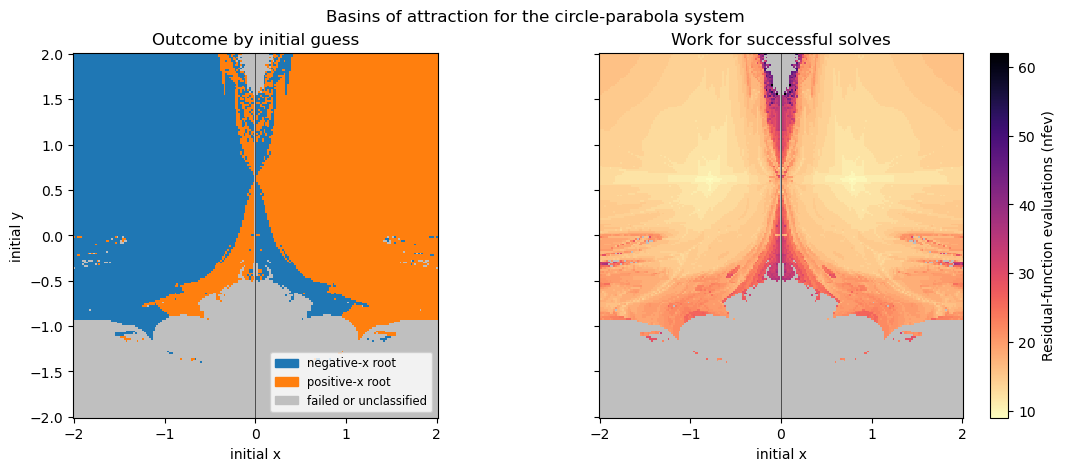

In [11]:
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.patches import Patch

basin_colormap = ListedColormap(["0.75", "tab:blue", "tab:orange"])
basin_norm = BoundaryNorm([-1.5, -0.5, 0.5, 1.5], basin_colormap.N)

fig, axes = plt.subplots(
    1, 2, figsize=(10.5, 4.6), constrained_layout=True, sharex=True, sharey=True
)
axes[0].pcolormesh(
    initial_coordinates,
    initial_coordinates,
    basin_id,
    cmap=basin_colormap,
    norm=basin_norm,
    shading="nearest",
)
axes[0].legend(
    handles=[
        Patch(color="tab:blue", label="negative-x root"),
        Patch(color="tab:orange", label="positive-x root"),
        Patch(color="0.75", label="failed or unclassified"),
    ],
    loc="lower right",
    fontsize="small",
)
axes[0].set_title("Outcome by initial guess")

successful_evaluations = np.ma.masked_where(
    basin_id < 0, function_evaluations
)
effort_colormap = plt.colormaps["magma_r"].copy()
effort_colormap.set_bad("0.75")
effort_image = axes[1].pcolormesh(
    initial_coordinates,
    initial_coordinates,
    successful_evaluations,
    cmap=effort_colormap,
    shading="nearest",
)
colorbar = fig.colorbar(effort_image, ax=axes[1])
colorbar.set_label("Residual-function evaluations (nfev)")
axes[1].set_title("Work for successful solves")

for ax in axes:
    ax.axvline(0.0, color="black", linewidth=0.7, alpha=0.6)
    ax.set(xlabel="initial x", aspect="equal")
axes[0].set_ylabel("initial y")
fig.suptitle("Basins of attraction for the circle-parabola system")

The broad left-right symmetry is expected from the equations, but the interleaved outcomes, sizeable failure regions, and increased effort near their boundaries are not obvious from the two isolated successful solves. Grey cells are deliberately retained: assigning them to the nearest root would conceal solver failures.

The entire initial line $x=0$ is problematic. Along this line, the first column of $J_F(0,y)$ is zero, so the Jacobian is singular for every initial value of $y$. Changing the solver method, tolerances, variable scaling, or SciPy version may change the detailed boundaries. Avoid calling the visible structure fractal without a separate resolution study.

### Comparing default solver behaviour

The default [`hybr` method](https://docs.scipy.org/doc/scipy/reference/optimize.root-hybr.html) uses a modified Powell hybrid algorithm to seek a zero of $F$. The [`lm` method](https://docs.scipy.org/doc/scipy/reference/optimize.root-lm.html) instead applies Levenberg–Marquardt to the nonlinear least-squares objective

$$
S(x,y) = \frac{1}{2}\lVert F(x,y)\rVert_2^2,
$$

where $S$ is the sum-of-squares objective and $F(x,y)$ is the vector of residuals. Every exact root has $S=0$, but a least-squares algorithm can terminate successfully with $S>0$—for example, after reaching a nonzero least-squares stationary point, where the gradient $\nabla S$ is zero, or after satisfying another method-specific stopping criterion. Therefore, the two methods' `success` flags do not make the same scientific claim.

The comparison below uses each method's default options, the same grid, and the same post-validation tolerances. It compares default behaviour rather than establishing that either method is universally superior. Computing the second map adds another `grid_size**2` solves, so the complete comparison performs `2*grid_size**2` solver calls.

In [12]:
(
    lm_basin_id,
    lm_function_evaluations,
    lm_reported_success,
    lm_residual_norm,
) = scan_initial_points("lm")

In [13]:
def summarize_solver(method, basin, evaluations, reported_success):
    """Return validation and work summaries for one solver method."""
    validated_root = basin >= 0
    invalid_success = reported_success & ~validated_root
    validated_evaluations = evaluations[validated_root]
    return (
        method,
        100.0 * np.mean(reported_success),
        100.0 * np.mean(validated_root),
        100.0 * np.mean(invalid_success),
        np.median(validated_evaluations),
        np.percentile(validated_evaluations, 95),
    )


solver_summaries = [
    summarize_solver(
        "hybr", basin_id, function_evaluations, hybr_reported_success
    ),
    summarize_solver(
        "lm", lm_basin_id, lm_function_evaluations, lm_reported_success
    ),
]

print(
    f"{'method':<8} {'reported success':>17} {'validated root':>16} "
    f"{'success, not root':>19} {'median nfev':>13} {'95% nfev':>10}"
)
for method, reported, validated, invalid, median_nfev, p95_nfev in solver_summaries:
    print(
        f"{method:<8} {reported:16.2f}% {validated:15.2f}% "
        f"{invalid:18.2f}% {median_nfev:13.0f} {p95_nfev:10.0f}"
    )

method    reported success   validated root   success, not root   median nfev   95% nfev
hybr                69.94%           69.94%               0.00%            15         25
lm                  99.25%           66.70%              32.55%            21         29


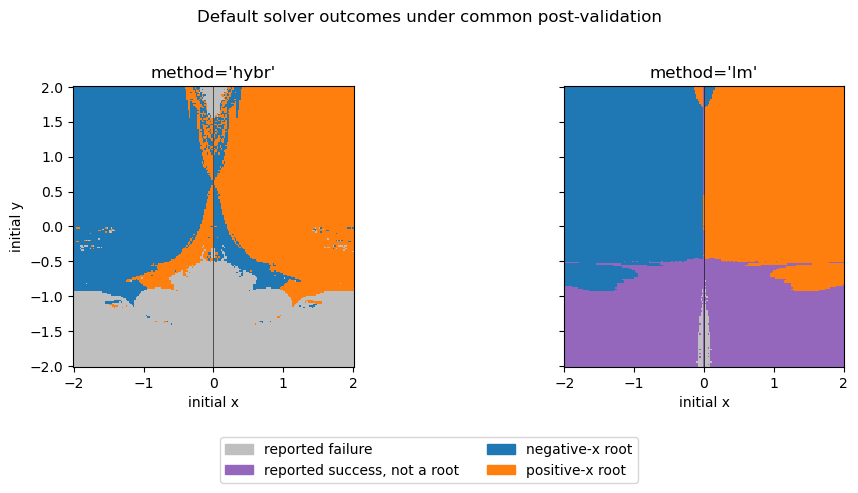

In [14]:
def detailed_outcomes(basin, reported_success):
    """Separate reported failures from successful non-roots."""
    return np.where(
        basin >= 0, basin, np.where(reported_success, -1, -2)
    )


hybr_outcomes = detailed_outcomes(basin_id, hybr_reported_success)
lm_outcomes = detailed_outcomes(lm_basin_id, lm_reported_success)
comparison_colormap = ListedColormap([
    "0.75", "tab:purple", "tab:blue", "tab:orange"
])
comparison_norm = BoundaryNorm(
    [-2.5, -1.5, -0.5, 0.5, 1.5], comparison_colormap.N
)

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.9), sharex=True, sharey=True)
for ax, outcomes, method in zip(
    axes, [hybr_outcomes, lm_outcomes], ["hybr", "lm"], strict=True
):
    ax.pcolormesh(
        initial_coordinates,
        initial_coordinates,
        outcomes,
        cmap=comparison_colormap,
        norm=comparison_norm,
        shading="nearest",
    )
    ax.axvline(0.0, color="black", linewidth=0.7, alpha=0.6)
    ax.set(title=f"method='{method}'", xlabel="initial x", aspect="equal")
axes[0].set_ylabel("initial y")
fig.legend(
    handles=[
        Patch(color="0.75", label="reported failure"),
        Patch(color="tab:purple", label="reported success, not a root"),
        Patch(color="tab:blue", label="negative-x root"),
        Patch(color="tab:orange", label="positive-x root"),
    ],
    loc="lower center",
    bbox_to_anchor=(0.5, 0.0),
    ncol=2,
)
fig.suptitle("Default solver outcomes under common post-validation")
fig.tight_layout(rect=[0.0, 0.14, 1.0, 0.95])

In [15]:
origin = np.array([0.0, 0.0])
for method in ("hybr", "lm"):
    origin_result = root(residual, origin, method=method)
    print(
        f"{method:4s}: success={str(origin_result.success):5s}, "
        f"point={origin_result.x}, "
        f"||F||_2={np.linalg.norm(origin_result.fun):.6f}"
    )

hybr: success=False, point=[0. 0.], ||F||_2=1.000000
lm  : success=True , point=[7.07106781e-01 6.88981808e-16], ||F||_2=0.707107


Purple regions are the essential result: `lm` reported successful termination, but the common residual-and-root validation rejected the returned point. The origin provides a particularly clear example. In this run, `hybr` reports failure there, whereas `lm` reports success at a point with a visibly nonzero residual norm.

For the original root-finding problem, any returned point for which $\lVert F(x,y)\rVert_2$ exceeds `residual_tolerance` is not a valid solution and must be rejected, even when `result.success` is `True`. Here, $F(x,y)$ is the residual vector and $\lVert F(x,y)\rVert_2$ is its Euclidean norm.

This does not make Levenberg–Marquardt defective. It demonstrates that successful termination of a least-squares algorithm need not mean that an exact root was found. Conversely, the comparison does not prove that `hybr` is generally better: it uses one small system, one domain of initial guesses, method-specific default stopping rules, and fixed post-validation tolerances. The reported `nfev` values count residual calls but omit other internal work, so they are not a complete performance benchmark.

## Exercise: intersect a circle and a line

Replace the parabola by the line $y=x+0.2$ and solve

$$
G_1(x,y)=x^2+y^2-1=0,
$$

$$
G_2(x,y)=y-x-0.2=0.
$$

Here, $G_1$ and $G_2$ are the two new residuals. Write a residual function, choose two initial guesses that find different intersections, and verify the returned solutions using both `success` and the residual norm. The exact intersections are $(0.6,0.8)$ and $(-0.8,-0.6)$, which you may use as an independent check.

### One solution

In [16]:
def circle_line_residual(coordinates: np.ndarray) -> np.ndarray:
    """Return the circle and line residuals at ``coordinates``."""
    x, y = coordinates
    return np.array([
        x**2 + y**2 - 1.0,
        y - x - 0.2,
    ])


exercise_guesses = np.array([
    [1.0, 1.0],
    [-1.0, -1.0],
])
exercise_results = [
    root(circle_line_residual, guess) for guess in exercise_guesses
]

for guess, current_result in zip(exercise_guesses, exercise_results, strict=True):
    residual_norm = np.linalg.norm(current_result.fun)
    assert current_result.success
    assert residual_norm < 1.0e-10
    print(
        f"initial guess {guess} -> root {current_result.x}, "
        f"||G||_2={residual_norm:.3e}"
    )

initial guess [1. 1.] -> root [0.6 0.8], ||G||_2=1.333e-15
initial guess [-1. -1.] -> root [-0.8 -0.6], ||G||_2=1.333e-15


## Limitations and next steps

The example is intentionally well scaled and has as many equations as unknowns. Real systems may require additional care:

- A successful local solve does not establish that every root has been found.
- Poorly scaled unknowns or residuals can impair convergence.
- Supplying an accurate Jacobian can reduce work or improve robustness for some methods.
- If there are more residuals than unknowns, measurements contain noise, or no exact root is expected, `scipy.optimize.least_squares` is often a better model of the problem.
- Bounds and physical constraints require an algorithm that supports them; `root` does not enforce general bounds.

Always interpret convergence information together with residuals and the scientific meaning of the returned solution.